# DATA 266 - HW 9

**Author:** Siva Surya Chandran  
**Topic:** Latent diffusion on Fashion-MNIST (VAE latent space, class-conditional U-Net, classifier-free guidance)

This notebook is meant to be run from the first cell to the last. A frozen pretrained VAE (`stabilityai/sd-vae-ft-mse`) compresses each image into a latent, which I scale by 0.18215. The diffusion model then works entirely in that latent space (T=1000, linear beta from 1e-4 to 0.02). A U-Net predicts the noise given the timestep and a class label, and sampling uses classifier-free guidance with w=3 before the VAE decoder turns the latent back into an image.

Fashion-MNIST images are 28x28 grayscale. The VAE downsamples by 8, and the assignment wants self-attention at 16x16, so I resize each image to 128x128 and repeat it to 3 channels. That gives a 4x16x16 latent.

In [1]:
# Step 0 - standing personal parameters
SID4 = 3215
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10
print(f"SID4={SID4} SEED={SEED} SLICE={SLICE} HP_ID={HP_ID} CLS_A={CLS_A} CLS_B={CLS_B}")
print("HW9 has no assignment-specific HP_ID mapping; the VAE and the diffusion U-Net are the two trained/used models, configuration fixed by the assignment.")

SID4=3215 SEED=3215 SLICE=215 HP_ID=5 CLS_A=5 CLS_B=2
HW9 has no assignment-specific HP_ID mapping; the VAE and the diffusion U-Net are the two trained/used models, configuration fixed by the assignment.


In [2]:
import json, time, random, math, os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from diffusers import AutoencoderKL

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
ROOT = Path.cwd(); OUT=ROOT/'outputs'; CKPT=ROOT/'checkpoints'; FIG=ROOT/'figures'; DATA=ROOT/'data'
for p in (OUT, CKPT, FIG, DATA): p.mkdir(exist_ok=True)
print("torch", torch.__version__, "device", DEVICE)

# Assignment configuration
T = 1000; BETA_START = 1e-4; BETA_END = 0.02
SCALE = 0.18215                 # standard SD VAE latent scaling factor s
IMG = 128                       # 128 / 8 = 16x16 latent
BATCH_SIZE = 128; EPOCHS = 50; LR = 2e-5
P_DROP = 0.1; NUM_CLASSES = 10; NULL = 10; GUIDE_W = 3.0
CLASSES = ['T-shirt/top','Trouser','Pullover','Dress','Coat','Sandal','Shirt','Sneaker','Bag','Ankle boot']
results = {}

W1102 13:20:13.081000 29199 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


torch 2.15.0 device mps


## 1. VAE compression and latent representation

Load the frozen pretrained VAE, encode every Fashion-MNIST training image, scale the latents by $s=0.18215$, and verify reconstruction by decoding $z/s$ (the scaled latents divided back by $s$ is exactly what the decoder expects) and computing MSE against the original input.

Encoding uses the posterior mean (deterministic), computed once and cached to disk. Images are scaled to $[-1,1]$, which is the range the VAE was trained on.

In [3]:
vae = AutoencoderKL.from_pretrained('stabilityai/sd-vae-ft-mse').to(DEVICE).eval()
for p in vae.parameters(): p.requires_grad_(False)
print("VAE params (M):", sum(p.numel() for p in vae.parameters())/1e6)

tf = transforms.Compose([transforms.ToTensor()])           # [0,1], 28x28
train_ds = datasets.FashionMNIST(DATA, train=True, download=True, transform=tf)
print("train images:", len(train_ds))

def prep(x01):                                              # (B,1,28,28) in [0,1] -> (B,3,128,128) in [-1,1]
    x = F.interpolate(x01, size=(IMG, IMG), mode='bilinear', align_corners=False)
    return (x.repeat(1, 3, 1, 1) * 2 - 1).clamp(-1, 1)

@torch.no_grad()
def encode(x01):  return vae.encode(prep(x01).to(DEVICE)).latent_dist.mean * SCALE
@torch.no_grad()
def decode(z):    return (vae.decode(z.to(DEVICE) / SCALE).sample.clamp(-1, 1) + 1) / 2   # -> [0,1], 3ch

LAT = CKPT/'latents.pt'
if LAT.exists():
    d = torch.load(LAT); Z, Y = d['z'], d['y']
else:
    t0 = time.time(); zs, ys = [], []
    loader = DataLoader(train_ds, batch_size=64, shuffle=False, num_workers=0)
    for i, (x, y) in enumerate(loader):
        zs.append(encode(x).cpu()); ys.append(y)
        if i % 100 == 0: print(f"encoded {i*64}/{len(train_ds)}  {time.time()-t0:.0f}s", flush=True)
    Z, Y = torch.cat(zs), torch.cat(ys)
    torch.save({'z': Z, 'y': Y}, LAT)
    results['encode_seconds'] = time.time()-t0
print("latents:", tuple(Z.shape), "labels:", tuple(Y.shape))
print(f"scaled latent mean={Z.mean():.4f} std={Z.std():.4f}  (target ~unit variance after scaling)")
results['latent_mean']=Z.mean().item(); results['latent_std']=Z.std().item()

/Users/sivasuryachandran/Documents/Fall26/DATA 266/DATA266-3215/HW9/.venv/lib/python3.15/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


VAE params (M): 83.653863


  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  0%|          | 32.8k/26.4M [00:00<01:52, 235kB/s]

  0%|          | 65.5k/26.4M [00:00<02:08, 205kB/s]

  0%|          | 131k/26.4M [00:00<01:28, 296kB/s] 

... (36 outputs left out)

encoded 44800/60000  1080s


encoded 51200/60000  1232s


encoded 57600/60000  1385s


latents: (60000, 4, 16, 16) labels: (60000,)
scaled latent mean=-0.0391 std=1.2652  (target ~unit variance after scaling)


Reconstruction MSE over 1024 images: 0.00019 (pixel range [0,1]); = 0.00077 on the [-1,1] scale; PSNR ~ 37.59 dB


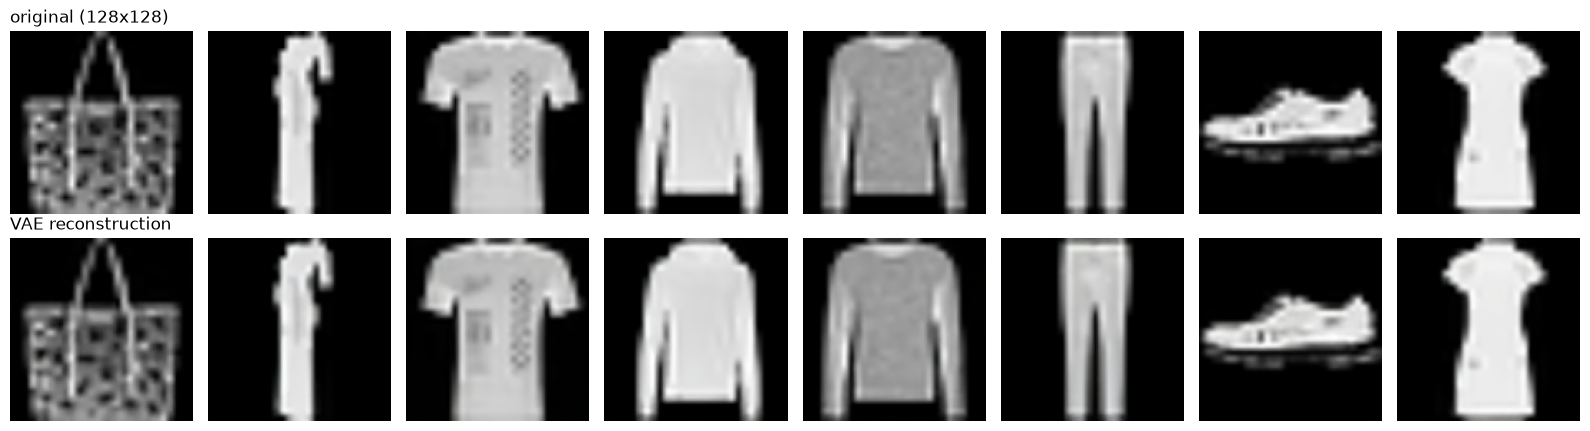

In [4]:
# Reconstruction check: decode the scaled latents and compare with the original input (MSE)
set_seed()
g = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(train_ds), generator=g)[:1024]
mses01, mses_pm1 = [], []
for k in range(0, len(idx), 64):
    b = idx[k:k+64]
    x01 = torch.stack([train_ds[i][0] for i in b])
    ref = (prep(x01).to(DEVICE) + 1) / 2                    # resized 3-channel input in [0,1]
    rec = decode(Z[b].to(DEVICE))
    mses01.append(F.mse_loss(rec, ref, reduction='none').mean((1,2,3)).cpu())
mses01 = torch.cat(mses01)
print(f"Reconstruction MSE over {len(idx)} images: {mses01.mean():.5f} (pixel range [0,1]); "
      f"= {4*mses01.mean():.5f} on the [-1,1] scale; PSNR ~ {(-10*torch.log10(mses01)).mean():.2f} dB")
results['recon_mse_01'] = mses01.mean().item(); results['recon_mse_pm1'] = 4*mses01.mean().item()

b = idx[:8]; x01 = torch.stack([train_ds[i][0] for i in b])
ref = (prep(x01).to(DEVICE)+1)/2; rec = decode(Z[b].to(DEVICE))
fig, ax = plt.subplots(2, 8, figsize=(16, 4.4))
for i in range(8):
    ax[0,i].imshow(ref[i].permute(1,2,0).cpu()); ax[0,i].axis('off')
    ax[1,i].imshow(rec[i].permute(1,2,0).cpu()); ax[1,i].axis('off')
ax[0,0].set_title('original (128x128)', loc='left'); ax[1,0].set_title('VAE reconstruction', loc='left')
plt.tight_layout(); plt.savefig(FIG/'vae_reconstruction.png', dpi=110); plt.show()

## 2. Forward diffusion in latent space

$$q(z_t\mid z_0)=\mathcal N\big(z_t;\sqrt{\bar\alpha_t}\,z_0,(1-\bar\alpha_t)I\big),\qquad T=1000,\ \beta_t\ \text{linear in}\ [10^{-4},0.02].$$

Equivalently $z_t=\sqrt{\bar\alpha_t}z_0+\sqrt{1-\bar\alpha_t}\,\epsilon$. Timestep $t\in\{1,\dots,T\}$ is stored at array index $t-1$; $t=0$ means the clean latent.

abar_1=0.99990  abar_200=0.6590  abar_500=0.0786  abar_800=0.00153  abar_T=4.04e-05


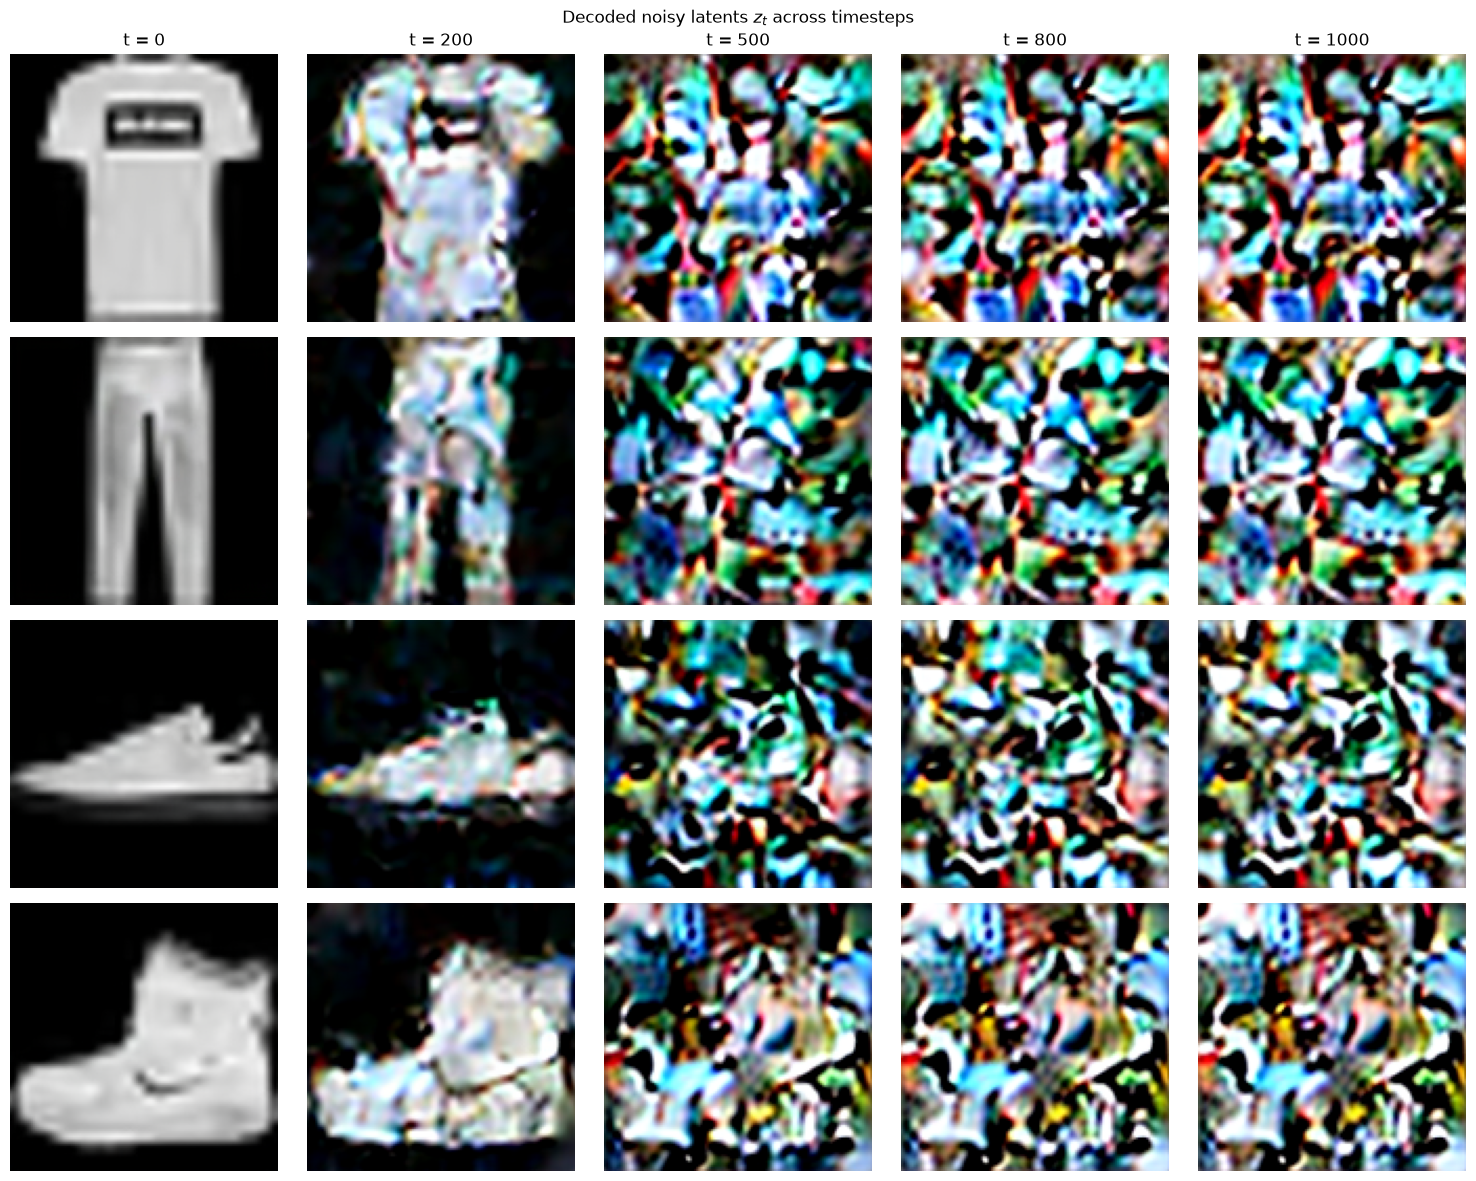

In [5]:
betas = torch.linspace(BETA_START, BETA_END, T, device=DEVICE)
alphas = 1 - betas
abar = torch.cumprod(alphas, 0)
abar_prev = torch.cat([torch.ones(1, device=DEVICE), abar[:-1]])
print(f"abar_1={abar[0]:.5f}  abar_200={abar[199]:.4f}  abar_500={abar[499]:.4f}  abar_800={abar[799]:.5f}  abar_T={abar[-1]:.2e}")
results['abar_T'] = abar[-1].item()

def add_noise(z0, t, eps=None):
    # t: LongTensor of timesteps in 0..T (0 = clean). Returns z_t and eps.
    if eps is None: eps = torch.randn_like(z0)
    ab = torch.where(t > 0, abar[(t-1).clamp(min=0)], torch.ones_like(t, dtype=abar.dtype))
    ab = ab.view(-1, 1, 1, 1)
    return ab.sqrt()*z0 + (1-ab).sqrt()*eps, eps

set_seed()
vis_ids = [0, 1, 2, 3, 4, 5, 7, 9]
vis_idx = [int((Y == c).nonzero()[0]) for c in [0, 1, 7, 9]]       # one example each of 4 classes
z0 = Z[vis_idx].to(DEVICE)
steps = [0, 200, 500, 800, 1000]
fig, ax = plt.subplots(len(vis_idx), len(steps), figsize=(3*len(steps), 3*len(vis_idx)))
eps = torch.randn_like(z0)
for j, t in enumerate(steps):
    zt, _ = add_noise(z0, torch.full((len(z0),), t, device=DEVICE, dtype=torch.long), eps)
    img = decode(zt).cpu()
    for i in range(len(z0)):
        ax[i,j].imshow(img[i].permute(1,2,0)); ax[i,j].axis('off')
        if i == 0: ax[i,j].set_title(f"t = {t}")
plt.suptitle("Decoded noisy latents $z_t$ across timesteps"); plt.tight_layout()
plt.savefig(FIG/'forward_diffusion.png', dpi=110); plt.show()

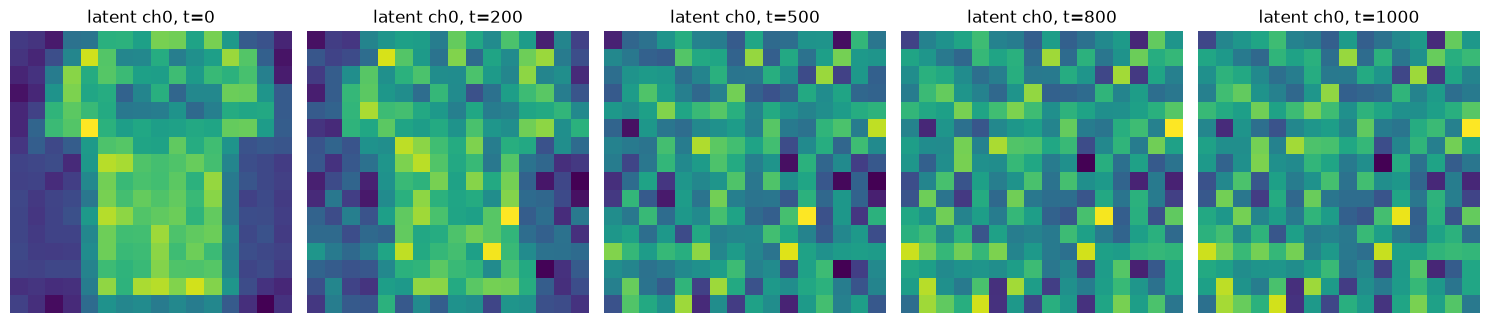

sqrt(abar_t) at the five timesteps: [1.0, 0.8118, 0.2803, 0.0391, 0.0064]


In [6]:
# Also show the noisy latents themselves (first latent channel) to see what the decoder is being fed
fig, ax = plt.subplots(1, len(steps), figsize=(3*len(steps), 3.2))
for j, t in enumerate(steps):
    zt, _ = add_noise(z0[:1], torch.tensor([t], device=DEVICE), eps[:1])
    ax[j].imshow(zt[0,0].cpu(), cmap='viridis'); ax[j].set_title(f"latent ch0, t={t}"); ax[j].axis('off')
plt.tight_layout(); plt.savefig(FIG/'forward_latent_channel0.png', dpi=110); plt.show()
print("sqrt(abar_t) at the five timesteps:", [round(float(1.0 if t==0 else abar[t-1].sqrt()),4) for t in steps])

## 3. Conditional denoising U-Net

Architecture (as specified):

- Input/output: 4x16x16 latent; the network predicts the noise $\epsilon$ (4 channels).
- Base channels 64, multipliers (1, 2, 4) -> 64 / 128 / 256 channels at 16x16 / 8x8 / 4x4.
- Sinusoidal time embedding followed by an MLP.
- Residual blocks with GroupNorm + SiLU; the conditioning vector is added inside each block.
- Self-attention at the 16x16 resolution and in the bottleneck.
- Strided-conv downsampling, nearest-neighbour + conv upsampling, skip connections.
- Classifier-free guidance: label embedding table with 10 classes + 1 null label, added to the time embedding; labels are replaced by the null label with probability 0.1 during training.

In [7]:
def timestep_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    a = t.float()[:, None] * freqs[None]
    return torch.cat([a.sin(), a.cos()], dim=1)

class ResBlock(nn.Module):
    def __init__(self, cin, cout, emb_dim, groups=8):
        super().__init__()
        self.n1 = nn.GroupNorm(groups, cin);  self.c1 = nn.Conv2d(cin, cout, 3, padding=1)
        self.emb = nn.Linear(emb_dim, cout)
        self.n2 = nn.GroupNorm(groups, cout); self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, emb):
        h = self.c1(F.silu(self.n1(x)))
        h = h + self.emb(F.silu(emb))[:, :, None, None]
        h = self.c2(F.silu(self.n2(h)))
        return h + self.skip(x)

class SelfAttention(nn.Module):
    def __init__(self, ch, heads=4, groups=8):
        super().__init__()
        self.norm = nn.GroupNorm(groups, ch); self.qkv = nn.Conv2d(ch, 3*ch, 1); self.proj = nn.Conv2d(ch, ch, 1); self.heads = heads
    def forward(self, x):
        B, C, H, W = x.shape
        q, k, v = self.qkv(self.norm(x)).reshape(B, 3, self.heads, C//self.heads, H*W).permute(1, 0, 2, 4, 3)
        o = F.scaled_dot_product_attention(q, k, v)                      # (B, heads, HW, C/heads)
        return x + self.proj(o.permute(0, 1, 3, 2).reshape(B, C, H, W))

class Down(nn.Module):
    def __init__(self, c): super().__init__(); self.conv = nn.Conv2d(c, c, 3, stride=2, padding=1)
    def forward(self, x): return self.conv(x)
class Up(nn.Module):
    def __init__(self, c): super().__init__(); self.conv = nn.Conv2d(c, c, 3, padding=1)
    def forward(self, x): return self.conv(F.interpolate(x, scale_factor=2, mode='nearest'))

class UNet(nn.Module):
    def __init__(self, in_ch=4, base=64, mults=(1, 2, 4), n_res=2, num_classes=10, attn_res=(16,), res0=16):
        super().__init__()
        emb = base * 4; self.base = base
        self.time_mlp = nn.Sequential(nn.Linear(base, emb), nn.SiLU(), nn.Linear(emb, emb))
        self.label_emb = nn.Embedding(num_classes + 1, emb)             # last index = null label
        self.inp = nn.Conv2d(in_ch, base, 3, padding=1)
        self.down = nn.ModuleList(); chans = [base]; ch = base; res = res0
        for li, m in enumerate(mults):
            for _ in range(n_res):
                blocks = [ResBlock(ch, base*m, emb)]; ch = base*m
                if res in attn_res: blocks.append(SelfAttention(ch))
                self.down.append(nn.ModuleList(blocks)); chans.append(ch)
            if li < len(mults)-1:
                self.down.append(nn.ModuleList([Down(ch)])); chans.append(ch); res //= 2
        self.mid = nn.ModuleList([ResBlock(ch, ch, emb), SelfAttention(ch), ResBlock(ch, ch, emb)])
        self.up = nn.ModuleList()
        for li, m in reversed(list(enumerate(mults))):
            for k in range(n_res + 1):
                blocks = [ResBlock(ch + chans.pop(), base*m, emb)]; ch = base*m
                if res in attn_res: blocks.append(SelfAttention(ch))
                if li > 0 and k == n_res: blocks.append(Up(ch)); res *= 2
                self.up.append(nn.ModuleList(blocks))
        self.out = nn.Sequential(nn.GroupNorm(8, ch), nn.SiLU(), nn.Conv2d(ch, in_ch, 3, padding=1))
    def _run(self, blocks, h, emb):
        for b in blocks: h = b(h, emb) if isinstance(b, ResBlock) else b(h)
        return h
    def forward(self, x, t, y):
        emb = self.time_mlp(timestep_embedding(t, self.base)) + self.label_emb(y)   # combine time + label
        h = self.inp(x); hs = [h]
        for blocks in self.down: h = self._run(blocks, h, emb); hs.append(h)
        h = self._run(self.mid, h, emb)
        for blocks in self.up: h = self._run(blocks, torch.cat([h, hs.pop()], 1), emb)
        return self.out(h)

set_seed()
model = UNet().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"U-Net parameters: {n_params:,}")
results['unet_params'] = n_params
with torch.no_grad():
    o = model(torch.randn(4, 4, 16, 16, device=DEVICE), torch.randint(1, T, (4,), device=DEVICE), torch.randint(0, 11, (4,), device=DEVICE))
print("output shape:", tuple(o.shape))

U-Net parameters: 14,494,340


output shape: (4, 4, 16, 16)


## 4. Training

Each step: sample a minibatch of latents, a uniform $t\in\{1..T\}$, noise $\epsilon$; form $z_t$; with probability 0.1 replace the label with the null label; minimise $\|\epsilon-\epsilon_\theta(z_t,t,y)\|^2$. 50 epochs, Adam, LR 2e-5 (as specified).

epoch 01/50 loss=0.39262  elapsed=210s


epoch 02/50 loss=0.18080  elapsed=413s


epoch 03/50 loss=0.14677  elapsed=637s


epoch 04/50 loss=0.13494  elapsed=859s


epoch 05/50 loss=0.12795  elapsed=1079s


epoch 06/50 loss=0.12279  elapsed=1298s


... (40 outputs left out)

epoch 47/50 loss=0.09310  elapsed=9094s


epoch 48/50 loss=0.09338  elapsed=9268s


epoch 49/50 loss=0.09192  elapsed=9443s


epoch 50/50 loss=0.09414  elapsed=9620s


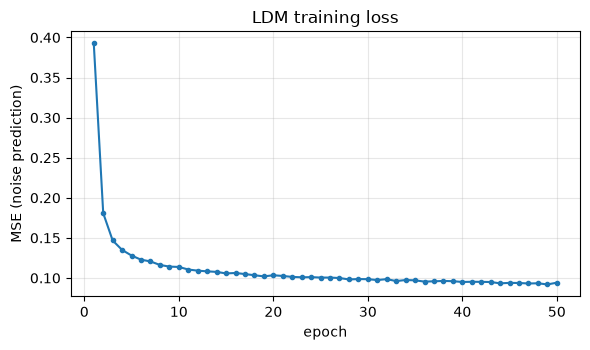

loss: epoch1=0.3926  final=0.0941


In [8]:
CK = CKPT/'ldm_unet.pt'
loader = DataLoader(TensorDataset(Z, Y), batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                    generator=torch.Generator().manual_seed(SEED), num_workers=0)
opt = torch.optim.Adam(model.parameters(), lr=LR)
losses = []
if CK.exists():
    ck = torch.load(CK, map_location=DEVICE); model.load_state_dict(ck['model']); losses = ck['losses']
    results['train_seconds'] = ck.get('train_seconds')
    print("loaded checkpoint; epochs trained:", len(losses))
else:
    set_seed(); t0 = time.time(); model.train()
    for ep in range(EPOCHS):
        tot, n = 0.0, 0
        for z0, y in loader:
            z0, y = z0.to(DEVICE), y.to(DEVICE)
            t = torch.randint(1, T+1, (z0.size(0),), device=DEVICE)
            zt, eps = add_noise(z0, t)
            y = torch.where(torch.rand(y.size(0), device=DEVICE) < P_DROP, torch.full_like(y, NULL), y)
            loss = F.mse_loss(model(zt, t-1, y), eps)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tot += loss.item(); n += 1
        losses.append(tot/n)
        print(f"epoch {ep+1:02d}/{EPOCHS} loss={losses[-1]:.5f}  elapsed={time.time()-t0:.0f}s", flush=True)
        torch.save({'model': model.state_dict(), 'losses': losses, 'train_seconds': time.time()-t0}, CK)
    results['train_seconds'] = time.time()-t0
model.eval()
results['loss_epoch1'] = losses[0]; results['loss_final'] = losses[-1]
plt.figure(figsize=(6,3.6)); plt.plot(range(1, len(losses)+1), losses, marker='o', ms=3)
plt.xlabel('epoch'); plt.ylabel('MSE (noise prediction)'); plt.title('LDM training loss'); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG/'training_loss.png', dpi=110); plt.show()
print(f"loss: epoch1={losses[0]:.4f}  final={losses[-1]:.4f}")

## 5. Sampling with classifier-free guidance

At every reverse step the network is evaluated twice (true label and null label) and combined as

$$\epsilon=(1+w)\,\epsilon_{\text{cond}}-w\,\epsilon_{\text{uncond}},\qquad w=3.$$

The combined $\epsilon$ is plugged into the ancestral DDPM update over all $T=1000$ steps,

$$z_{t-1}=\frac{1}{\sqrt{\alpha_t}}\Big(z_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon\Big)+\sigma_t\xi,\quad \sigma_t^2=\tilde\beta_t=\beta_t\frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t},$$

and the final latent is decoded by the VAE. The 64-image grid uses labels 0-9 repeated (0,1,...,9,0,1,...), 8 per row.

sampled 64 images, T=1000 steps, w=3.0: 123s


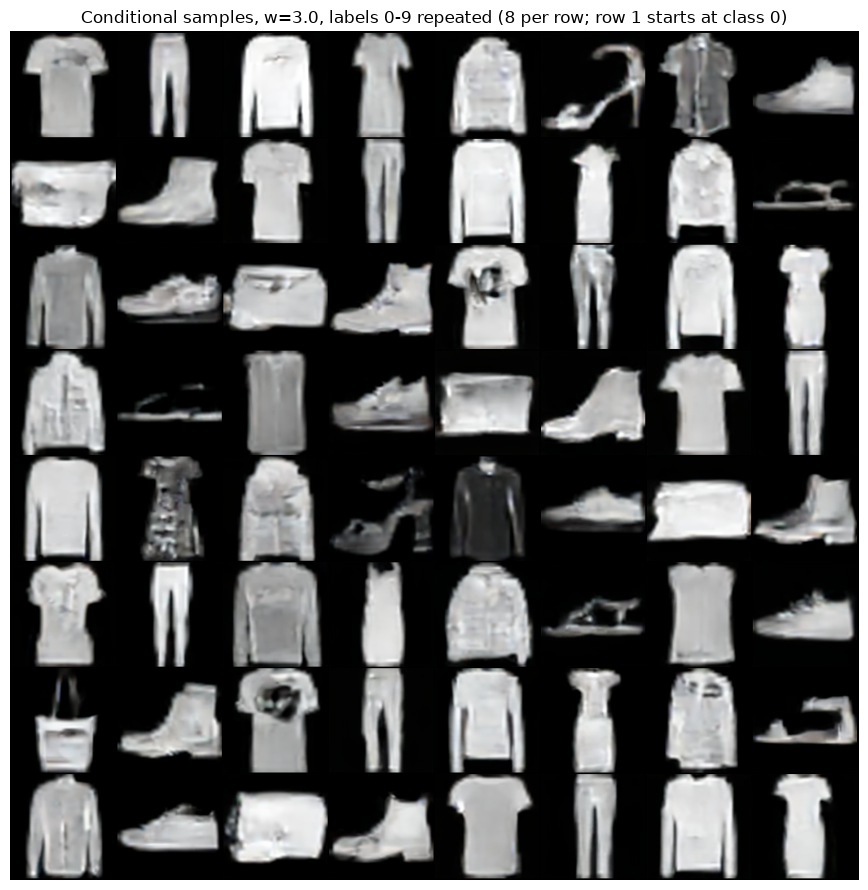

In [9]:
@torch.no_grad()
def sample(labels, w=GUIDE_W, seed=SEED, return_traj=False):
    g = torch.Generator(device='cpu').manual_seed(seed)
    n = len(labels); y = torch.as_tensor(labels, device=DEVICE); yn = torch.full_like(y, NULL)
    z = torch.randn(n, 4, 16, 16, generator=g).to(DEVICE)
    for i in reversed(range(T)):
        tt = torch.full((n,), i, device=DEVICE, dtype=torch.long)
        e = model(torch.cat([z, z]), torch.cat([tt, tt]), torch.cat([y, yn]))
        e_c, e_u = e.chunk(2)
        eps = (1 + w) * e_c - w * e_u
        mean = (z - betas[i] / (1 - abar[i]).sqrt() * eps) / alphas[i].sqrt()
        if i > 0:
            var = betas[i] * (1 - abar_prev[i]) / (1 - abar[i])
            z = mean + var.sqrt() * torch.randn(z.shape, generator=g).to(DEVICE)
        else:
            z = mean
    return z

labels64 = [i % 10 for i in range(64)]
t0 = time.time(); z_gen = sample(labels64); sample_secs = time.time()-t0
imgs = decode(z_gen).cpu(); results['sample_seconds_64'] = sample_secs
print(f"sampled 64 images, T={T} steps, w={GUIDE_W}: {sample_secs:.0f}s")
grid = make_grid(imgs, nrow=8, padding=2).permute(1,2,0)
plt.figure(figsize=(9,9)); plt.imshow(grid); plt.axis('off')
plt.title(f"Conditional samples, w={GUIDE_W}, labels 0-9 repeated (8 per row; row 1 starts at class 0)")
plt.tight_layout(); plt.savefig(FIG/'samples_w3.png', dpi=120); plt.show()

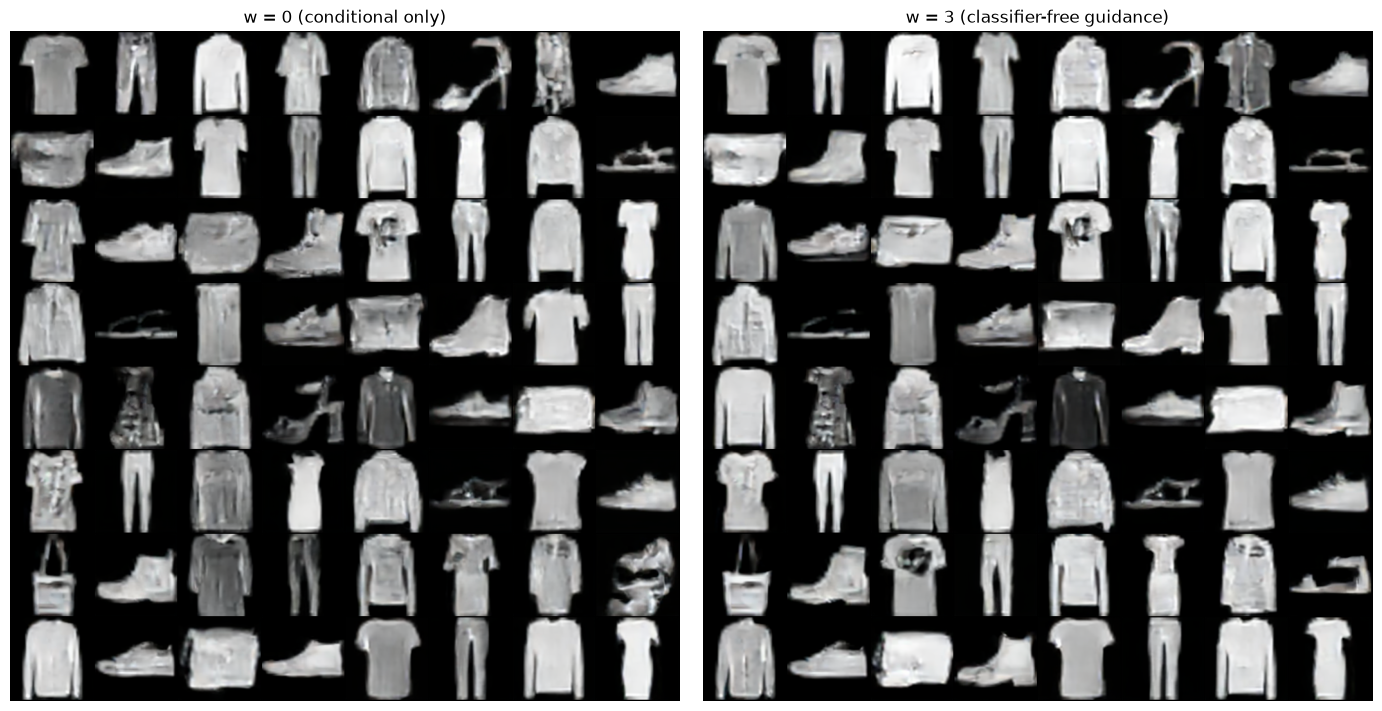

144s


In [10]:
# Same 64 initial noises and labels, guidance off (w=0) vs on (w=3), as a sanity check of the guidance term
t0 = time.time(); z_w0 = sample(labels64, w=0.0)
imgs0 = decode(z_w0).cpu()
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
for a, im, ttl in zip(ax, [imgs0, imgs], ['w = 0 (conditional only)', 'w = 3 (classifier-free guidance)']):
    a.imshow(make_grid(im, nrow=8, padding=2).permute(1,2,0)); a.axis('off'); a.set_title(ttl)
plt.tight_layout(); plt.savefig(FIG/'samples_w0_vs_w3.png', dpi=110); plt.show()
print(f"{time.time()-t0:.0f}s")

### Quick quantitative check

A small CNN classifier is trained for 3 epochs on real Fashion-MNIST (28x28) and used to label the generated images (decoded, converted to gray, downsampled to 28x28). The fraction of generated images where the classifier's prediction equals the requested label is a rough measure of class-conditioning. This is only a sanity check, not part of the assignment.

In [11]:
set_seed()
test_ds = datasets.FashionMNIST(DATA, train=False, download=True, transform=tf)
clf = nn.Sequential(nn.Conv2d(1,32,3,padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Conv2d(32,64,3,padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Flatten(), nn.Linear(64*7*7,128), nn.ReLU(), nn.Linear(128,10)).to(DEVICE)
o = torch.optim.Adam(clf.parameters(), 1e-3)
for ep in range(3):
    for x, y in DataLoader(train_ds, batch_size=128, shuffle=True):
        l = F.cross_entropy(clf(x.to(DEVICE)), y.to(DEVICE)); o.zero_grad(); l.backward(); o.step()
clf.eval()
xt = torch.stack([test_ds[i][0] for i in range(2000)]); yt = torch.tensor([test_ds[i][1] for i in range(2000)])
with torch.no_grad(): acc = (clf(xt.to(DEVICE)).argmax(1).cpu() == yt).float().mean().item()
print(f"classifier test accuracy (2000 test images): {acc:.3f}")

def to28(img3):                                  # decoded (B,3,128,128) in [0,1] -> (B,1,28,28)
    return F.interpolate(img3.mean(1, keepdim=True), size=(28,28), mode='bilinear', align_corners=False, antialias=True)

# larger evaluation set: 10 per class = 100 images for w=0 and w=3 (same noise)
lab100 = [i % 10 for i in range(100)]
z3 = sample(lab100, w=3.0, seed=SEED+1); z0_ = sample(lab100, w=0.0, seed=SEED+1)
ev = {}
for name, zz in [('w=0', z0_), ('w=3', z3)]:
    im = decode(zz); p = clf(to28(im)).softmax(1)
    ev[name] = {'class_match': (p.argmax(1).cpu() == torch.tensor(lab100)).float().mean().item(), 'confidence': p.max(1).values.mean().item()}
    print(name, ev[name])
results['classifier_acc'] = acc; results['cfg_eval_100_images'] = ev

classifier test accuracy (2000 test images): 0.903


w=0 {'class_match': 0.8299999833106995, 'confidence': 0.8337277173995972}


w=3 {'class_match': 1.0, 'confidence': 0.9577929973602295}


In [12]:
json.dump(results, open(OUT/'results.json', 'w'), indent=2)
print(json.dumps(results, indent=2))

{
  "encode_seconds": 1445.1973309516907,
  "latent_mean": -0.039146147668361664,
  "latent_std": 1.2651546001434326,
  "recon_mse_01": 0.00019202259136363864,
  "recon_mse_pm1": 0.0007680903654545546,
  "abar_T": 4.035827441839501e-05,
  "unet_params": 14494340,
  "train_seconds": 9620.48130607605,
  "loss_epoch1": 0.3926161025197078,
  "loss_final": 0.09414152302739458,
  "sample_seconds_64": 123.11212515830994,
  "classifier_acc": 0.902999997138977,
  "cfg_eval_100_images": {
    "w=0": {
      "class_match": 0.8299999833106995,
      "confidence": 0.8337277173995972
    },
    "w=3": {
      "class_match": 1.0,
      "confidence": 0.9577929973602295
    }
  }
}


## Analysis

**VAE compression.** A 128x128x3 image (49,152 values) becomes a 4x16x16 latent (1,024 values), about 48x smaller. Decoding the scaled latent (divided back by s) gives a reconstruction MSE of 1.9e-4 on the [0,1] scale (7.7e-4 on [-1,1], about 37.6 dB), so the VAE is not what limits image quality. After scaling by 0.18215 the latents have a std of 1.27 rather than exactly 1. The factor was chosen for natural images, and Fashion-MNIST (black background, one centered object) has a slightly different spread.

**Forward diffusion.** abar is 0.659 at t=200, 0.0786 at t=500, 0.00153 at t=800 and 4.0e-5 at t=1000. At t=200 the silhouette is still recognisable but colour artefacts show up, probably because the decoder is being given latents it never saw during training. By t=500 the decoded image is already unrecognisable, and t=800 and t=1000 look the same since almost no signal is left (sqrt(abar) is 0.039 and 0.006). Unlike HW8, abar_T is essentially 0 here, so starting sampling from N(0, I) is reasonable.

**Training.** The U-Net has 14.5M parameters. Loss went from 0.393 in epoch 1 to 0.094 in epoch 50 and was still creeping down, so the small learning rate (2e-5) probably leaves some quality on the table. I did not try other learning rates.

**Classifier-free guidance.** With the same starting noise and labels, w=0 and w=3 give the same overall layouts, but the w=3 images are cleaner and look more clearly like the requested class. A small CNN classifier (90.3% accurate on real test images) matched the requested class for 83% of 100 generated images at w=0 and 100% at w=3, with mean confidence 0.83 versus 0.96. This is only a rough check: 100 images is small, the classifier is imperfect, and higher guidance usually trades away diversity, which I did not measure (no FID either). I also only tried w=0 and w=3. In the 64-image grid at w=3 every class is recognisable, though some bags and shirts have texture artefacts.